# EDAB6808 Assignment 2 - Question 2: South African inflation forecasting
**Buhle Mbokodo (2024007920) and Reatile Seekoei (2021109463)**

This notebook develops the supplied notebook's SARIMA and Random Forest pipeline. The forecasting target is **official headline year-on-year CPI inflation (%) for all urban areas**. The monthly sample is January 2021–December 2025. Forecasts cover January–December 2026.

The central question is which model forecasts inflation most accurately using only observations available before each historical forecast origin. MAE and RMSE are in **percentage points**. A forecast close to 4% is not a model-selection criterion.

## 1. Data source, target and preparation
**Source:** Statistics South Africa (2026), *Consumer Price Index, December 2025*, statistical release P0141, published 21 January 2026, printed page 4 (PDF page 5). [Official release](https://www.statssa.gov.za/publications/P0141/P0141December2025.pdf).

The supplied CSV reproduces **Table B1**, the headline CPI index with December 2024 = 100. The companion **Table B2** provides the official year-on-year inflation rates for all 60 months. We retain B1 for inspection and use B2 as the modelling target. B2 measures the percentage change in CPI relative to the same month a year earlier. These published rates use the publisher's underlying CPI calculations; recomputing rates from the rounded B1 index can give slightly different values.

The original calculation, `100 * (CPI / CPI.shift(12) - 1)`, cannot produce 2021 inflation without 2020 CPI. Its first 12 missing values are unavailable historical denominators, not faulty CPI readings. We use the official B2 rates rather than imputing those months, combining rounded and official rates, or inventing 2020 observations. The B2 values below are a documented transcription of the same release; they are also exported as a companion CSV.

No external explanatory variables are added: the short sample favours a parsimonious comparison. No random split, scaling, outlier removal, interpolation or backfilling is used.

In [ ]:
import sys
import subprocess
import importlib.util

# Colab normally has these packages. Install only missing dependencies.
missing_packages = [name for name in ['pandas', 'numpy', 'matplotlib',
                    'statsmodels', 'sklearn', 'IPython']
                    if importlib.util.find_spec(name) is None]
if missing_packages:
    package_names = {'sklearn': 'scikit-learn'}
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q'] +
                          [package_names.get(name, name) for name in missing_packages])

from pathlib import Path
from io import StringIO
from itertools import product
import json
import warnings
import platform
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels
import statsmodels.api as sm
import sklearn
from IPython.display import display, Markdown
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEED = 42
OUTPUT = Path('question2_outputs')
OUTPUT.mkdir(exist_ok=True)
(OUTPUT / 'figures').mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 4.5), 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 4)
versions = {'Python': platform.python_version(), 'pandas': pd.__version__,
            'numpy': np.__version__, 'statsmodels': statsmodels.__version__,
            'scikit-learn': sklearn.__version__}
print('Environment:', versions)

def finish_figure(filename):
    plt.tight_layout()
    plt.savefig(OUTPUT / 'figures' / filename, dpi=240, bbox_inches='tight')
    plt.show()

Environment: {'Python': '3.13.15', 'pandas': '2.2.3', 'numpy': '2.1.3', 'statsmodels': '0.15.0', 'scikit-learn': '1.6.1'}


In [ ]:
CSV_NAME = 'Table B1 - CPI headline index numbers (Dec 2024=100) - Table B1.csv'
search_roots = [Path.cwd(), Path.cwd() / 'data', Path('/content'),
                Path('/content/data'), Path.cwd() / 'upload']
candidates = [root / CSV_NAME for root in search_roots if (root / CSV_NAME).is_file()]
if not candidates:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f'Place {CSV_NAME} beside the notebook or in data/.')
    uploaded = files.upload()
    candidates = [Path(name) for name in uploaded if Path(name).name == CSV_NAME]
if len(candidates) == 0:
    raise FileNotFoundError('The supplied Table B1 CSV was not found.')
DATA_PATH = candidates[0]
cpi_wide = pd.read_csv(DATA_PATH)
print('Supplied table shape:', cpi_wide.shape)
print('Input SHA-256:', hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())
display(cpi_wide)

MONTHS = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
required_columns = ['Year'] + MONTHS + ['Average']
assert set(required_columns).issubset(cpi_wide.columns), 'Unexpected Table B1 format.'
assert not cpi_wide['Year'].duplicated().any(), 'Duplicate year in Table B1.'
assert set(cpi_wide['Year']) == set(range(2021, 2026)), 'Expected five complete years.'
cpi_long = cpi_wide.melt(id_vars='Year', value_vars=MONTHS,
                         var_name='month_name', value_name='cpi_headline_index')
cpi_long['month_number'] = cpi_long['month_name'].map(
    {month: i + 1 for i, month in enumerate(MONTHS)})
cpi_long['date'] = pd.to_datetime(dict(year=cpi_long['Year'],
                                     month=cpi_long['month_number'], day=1))
cpi_long['cpi_headline_index'] = pd.to_numeric(
    cpi_long['cpi_headline_index'], errors='raise')
cpi = cpi_long.set_index('date')['cpi_headline_index'].sort_index().asfreq('MS')
assert len(cpi) == 60 and not cpi.isna().any() and (cpi > 0).all()
assert cpi.loc['2024-12-01'] == 100.0, 'Unexpected CPI base period.'

# Official Table B2 transcription; annual Average is deliberately excluded.
official_b2_csv = """Year,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
2021,3.2,2.9,3.2,4.4,5.2,4.9,4.6,4.9,5.0,5.0,5.5,5.9
2022,5.7,5.7,5.9,5.9,6.5,7.4,7.8,7.6,7.5,7.6,7.4,7.2
2023,6.9,7.0,7.1,6.8,6.3,5.4,4.7,4.8,5.4,5.9,5.5,5.1
2024,5.3,5.6,5.3,5.2,5.2,5.1,4.6,4.4,3.8,2.8,2.9,3.0
2025,3.2,3.2,2.7,2.8,2.8,3.0,3.5,3.3,3.4,3.6,3.5,3.6
"""
b2_wide = pd.read_csv(StringIO(official_b2_csv))
b2_long = b2_wide.melt(id_vars='Year', value_vars=MONTHS,
                       var_name='month_name', value_name='inflation_yoy_pct')
b2_long['month_number'] = b2_long['month_name'].map(
    {month: i + 1 for i, month in enumerate(MONTHS)})
b2_long['date'] = pd.to_datetime(dict(year=b2_long['Year'],
                                    month=b2_long['month_number'], day=1))
inflation = b2_long.set_index('date')['inflation_yoy_pct'].sort_index().asfreq('MS')
cpi_clean = pd.concat([cpi, inflation], axis=1)
derived_yoy = 100 * (cpi / cpi.shift(12) - 1)
cpi_clean['yoy_from_rounded_index_pct'] = derived_yoy
cpi_clean['rounding_difference_pp'] = derived_yoy - inflation
assert inflation.index.equals(pd.date_range('2021-01-01', '2025-12-01', freq='MS'))
assert not inflation.index.duplicated().any() and not inflation.isna().any()
assert inflation.loc['2022-07-01'] == 7.8 and inflation.loc['2025-12-01'] == 3.6
display(cpi_clean.head(15))
display(cpi_clean.isna().sum().rename('Missing values').to_frame())
print('Missing model targets:', inflation.isna().sum())
print('Max absolute difference from rounded-index calculation (pp):',
      cpi_clean['rounding_difference_pp'].abs().max())
cpi_clean.to_csv(OUTPUT / 'South_Africa_CPI_2021_2025.csv', index_label='month')
b2_wide.to_csv(OUTPUT / 'StatsSA_Table_B2_Inflation_2021_2025.csv', index=False)

Supplied table shape: (5, 14)
Input SHA-256: b9a3d78794d29be7100b7ff4fafcc0feb8df6d2e4bd36206fefc64f1ff8e8408


,Year,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,Average
0,2021,81.7,82.2,82.8,83.3,83.4,83.5,84.5,84.8,85.0,85.3,85.6,86.1,84.0
1,2022,86.3,86.8,87.7,88.2,88.8,89.8,91.1,91.3,91.4,91.7,92.0,92.3,89.8
2,2023,92.2,92.9,93.9,94.2,94.4,94.6,95.4,95.7,96.3,97.2,97.1,97.1,95.1
3,2024,97.2,98.1,98.9,99.1,99.3,99.4,99.8,99.9,100.0,99.9,99.9,100.0,99.3
4,2025,100.3,101.2,101.6,101.9,102.1,102.4,103.3,103.2,103.4,103.5,103.4,103.6,102.5


,cpi_headline_index,inflation_yoy_pct,yoy_from_rounded_index_pct,rounding_difference_pp
date,,,,
2021-01-01,81.7,3.2,NaN,NaN
2021-02-01,82.2,2.9,NaN,NaN
2021-03-01,82.8,3.2,NaN,NaN
2021-04-01,83.3,4.4,NaN,NaN
2021-05-01,83.4,5.2,NaN,NaN
2021-06-01,83.5,4.9,NaN,NaN
2021-07-01,84.5,4.6,NaN,NaN
2021-08-01,84.8,4.9,NaN,NaN
2021-09-01,85.0,5.0,NaN,NaN


,Missing values
cpi_headline_index,0
inflation_yoy_pct,0
yoy_from_rounded_index_pct,12
rounding_difference_pp,12


Missing model targets: 0
Max absolute difference from rounded-index calculation (pp): 0.14491017964071773


## 2. Exploratory time-series analysis
The CPI index describes the price level. Inflation describes its year-on-year percentage change: falling inflation can coexist with a rising index. We inspect the full sample descriptively; **model-order diagnostics use only 2021–2022**, before the tuning period. The full-sample decomposition is descriptive and is never a predictor. Five years are too short to identify stable seasonality confidently, especially in overlapping year-on-year rates.

,cpi_headline_index,inflation_yoy_pct
count,60.0000,60.0000
mean,94.1333,4.9933
std,6.8240,1.5125
min,81.7000,2.7000
25%,88.0750,3.5000
50%,95.0000,5.1000
75%,99.9000,5.9000
max,103.6000,7.8000


,mean,min,max,std
date,,,,
2021,4.5583,2.9,5.9,0.9624
2022,6.8500,5.7,7.8,0.8394
2023,5.9083,4.7,7.1,0.8826
2024,4.4333,2.8,5.6,1.0439
2025,3.2167,2.7,3.6,0.3243


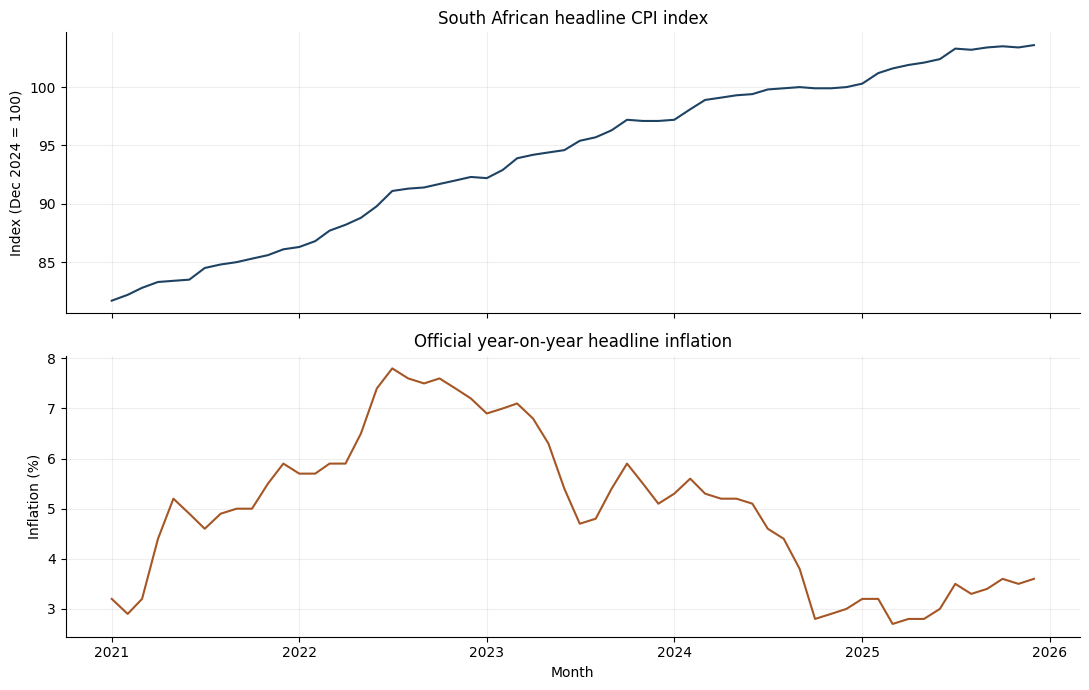

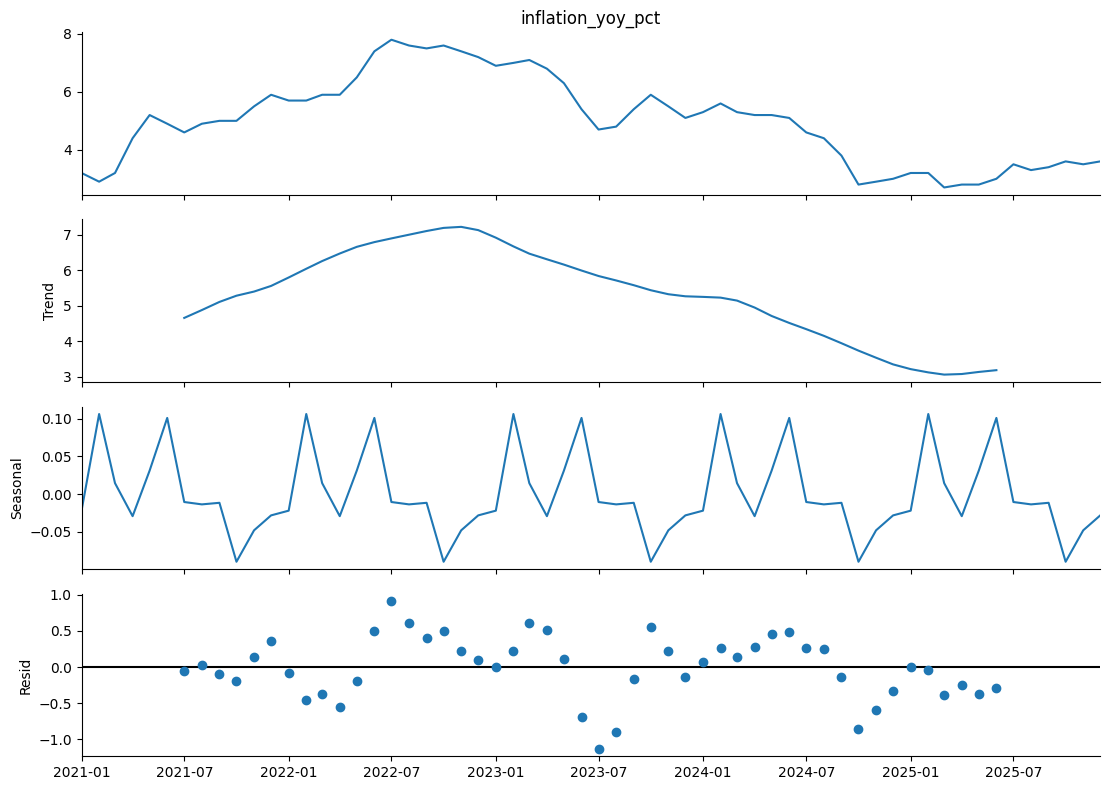

In [ ]:
display(cpi_clean[['cpi_headline_index', 'inflation_yoy_pct']].describe())
display(inflation.groupby(inflation.index.year).agg(['mean', 'min', 'max', 'std']))
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(cpi, color='#1E4262')
axes[0].set(title='South African headline CPI index', ylabel='Index (Dec 2024 = 100)')
axes[1].plot(inflation, color='#A55625')
axes[1].set(title='Official year-on-year headline inflation', ylabel='Inflation (%)', xlabel='Month')
for ax in axes: ax.grid(alpha=0.2)
finish_figure('01_cpi_and_inflation.png')

decomposition = seasonal_decompose(inflation, model='additive', period=12)
fig = decomposition.plot()
fig.set_size_inches(11, 8)
finish_figure('02_inflation_decomposition.png')

/tmp/ipykernel_2205/1926970688.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(series, regression='c', autolag='AIC', maxlag=3)
/tmp/ipykernel_2205/1926970688.py:7: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_result = kpss(series, regression='c', nlags='auto')
/tmp/ipykernel_2205/1926970688.py:5: FutureWarni

,Series,n,ADF statistic,ADF p-value,KPSS statistic,KPSS p-value (bounded)
0,Inflation level,24,-0.8933,7.9016e-01,0.6745,0.0159
1,First difference,23,-4.8879,3.6812e-05,0.1638,0.1000


ADF null: unit root. KPSS null: level stationarity.
Failing to reject a null does not prove it; both tests have low power with 24 months.


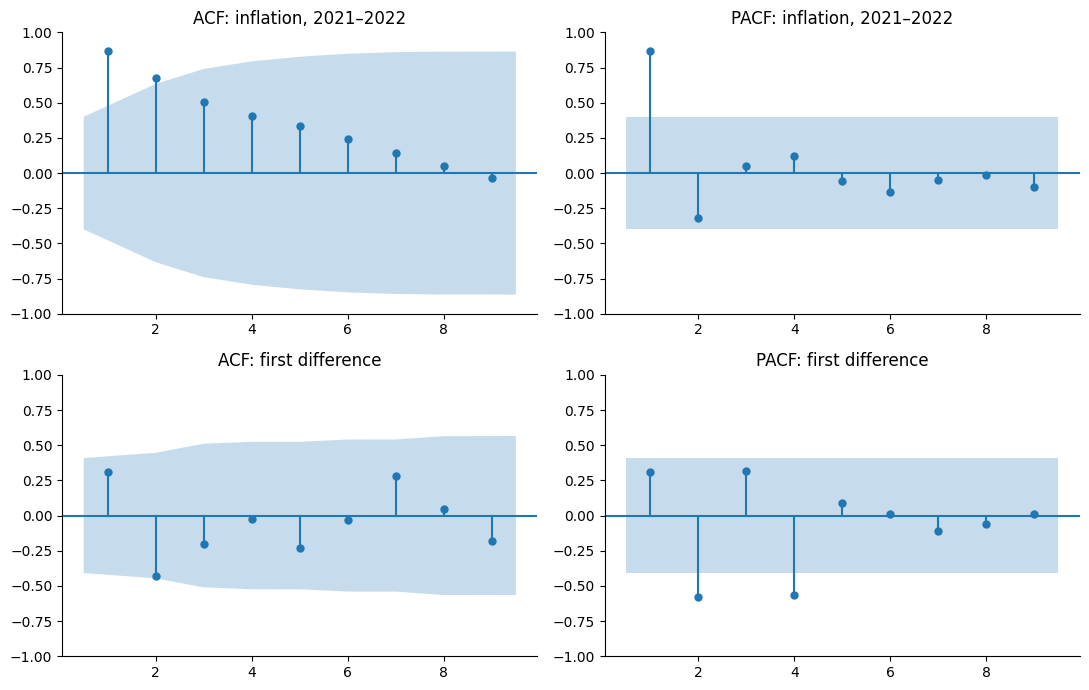

In [ ]:
diagnostic_train = inflation.loc[:'2022-12-01']
diagnostic_rows = []
for label, series in [('Inflation level', diagnostic_train),
                      ('First difference', diagnostic_train.diff().dropna())]:
    adf = adfuller(series, regression='c', autolag='AIC', maxlag=3)
    # KPSS tables have bounded p-values. Preserve this message in the output.
    kpss_result = kpss(series, regression='c', nlags='auto')
    diagnostic_rows.append({'Series': label, 'n': len(series),
                            'ADF statistic': adf[0], 'ADF p-value': adf[1],
                            'KPSS statistic': kpss_result[0],
                            'KPSS p-value (bounded)': kpss_result[1]})
stationarity_table = pd.DataFrame(diagnostic_rows)
display(stationarity_table)
print('ADF null: unit root. KPSS null: level stationarity.')
print('Failing to reject a null does not prove it; both tests have low power with 24 months.')
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
plot_acf(diagnostic_train, lags=9, ax=axes[0, 0], zero=False)
plot_pacf(diagnostic_train, lags=9, ax=axes[0, 1], method='ywm', zero=False)
plot_acf(diagnostic_train.diff().dropna(), lags=9, ax=axes[1, 0], zero=False)
plot_pacf(diagnostic_train.diff().dropna(), lags=9, ax=axes[1, 1], method='ywm', zero=False)
axes[0, 0].set_title('ACF: inflation, 2021–2022')
axes[0, 1].set_title('PACF: inflation, 2021–2022')
axes[1, 0].set_title('ACF: first difference')
axes[1, 1].set_title('PACF: first difference')
finish_figure('03_training_acf_pacf.png')

## 3. Forecasting design and leakage controls
The evaluation matches the task's **12-month forecast made from one origin**. Within each forecast path, future actual inflation is unavailable. SARIMA generates the entire path at once; Random Forest appends its own predictions to the historical series before building the next month's lag and rolling features.

| Stage | Available history / forecast origins | Scored months | Purpose |
|---|---|---|---|
| Initial diagnostics | Jan 2021–Dec 2022 | None | Inspect persistence and candidate transformations |
| Hyperparameter tuning | Dec 2022, Mar 2023, Jun 2023, Sep 2023; expanding training samples | Future months through Dec 2023 only; horizons 12, 9, 6, 3 | Choose one configuration per model family |
| Model selection | Dec 2023 | Jan–Dec 2024, one 12-step path | Choose statistical, ML or benchmark using RMSE |
| Locked historical check | Dec 2024 | Jan–Dec 2025, one 12-step path | Evaluate frozen choices without changing the winner |
| Supplementary one-step check | Each preceding month in 2025 | Jan–Dec 2025 | Show accuracy when new actuals become available monthly |
| Final fit | Jan 2021–Dec 2025 | Jan–Dec 2026 | Refit the selected configuration and forecast |

The tuning paths overlap, so their pooled error is a tuning score, not independent test evidence. Later tuning origins may use earlier observed 2023 values; each prediction still uses only data before its own origin. The 2025 scores never choose hyperparameters or the winning model. Selection uses 2024 RMSE, with MAE as a tie-breaker. If a simple benchmark wins, it is retained rather than forcing a more complex model.

This is a **fixed-vintage historical backtest** using the December 2025 release, not a reconstruction of each historical publication vintage. CPI release lags and revisions are not modelled. December 2025 data were published on 21 January 2026, so the final forecasts are conditional on that release, not information available on 31 December 2025. No 2026 target observations are used.

In [ ]:
TUNING_ORIGINS = pd.to_datetime(['2022-12-01', '2023-03-01',
                                '2023-06-01', '2023-09-01'])
TUNING_END = pd.Timestamp('2023-12-01')
SELECTION_ORIGIN = pd.Timestamp('2023-12-01')
CHECK_ORIGIN = pd.Timestamp('2024-12-01')
HORIZON = 12

def future_dates(history, steps):
    return pd.date_range(history.index[-1] + pd.offsets.MonthBegin(1),
                         periods=steps, freq='MS')

def forecast_metrics(actual, predicted, training):
    actual, predicted = np.asarray(actual, float), np.asarray(predicted, float)
    assert actual.shape == predicted.shape and len(actual) > 0
    assert np.isfinite(actual).all() and np.isfinite(predicted).all()
    scale = np.mean(np.abs(np.diff(np.asarray(training, float))))
    assert scale > 0
    denominator = np.abs(actual) + np.abs(predicted)
    return {'MAE_pp': mean_absolute_error(actual, predicted),
            'RMSE_pp': np.sqrt(mean_squared_error(actual, predicted)),
            'sMAPE_pct': np.mean(np.divide(200 * np.abs(actual - predicted),
                            denominator, out=np.zeros_like(actual), where=denominator > 0)),
            'MASE': np.mean(np.abs(actual - predicted)) / scale,
            'n_forecasts': len(actual)}

# MAE and RMSE quantify errors in percentage points; RMSE penalises larger misses.
# sMAPE is secondary because percentage metrics become unstable near zero inflation.
# MASE uses the mean one-step naive absolute error from each origin's training history.
# Therefore MASE < 1 is not a claim of beating a 12-month naive benchmark.
def pooled_metrics(records):
    rows = []
    for name, group in records.groupby('Model', sort=False):
        error = group['Actual'].to_numpy() - group['Forecast'].to_numpy()
        den = np.abs(group['Actual'].to_numpy()) + np.abs(group['Forecast'].to_numpy())
        rows.append({'Model': name, 'MAE_pp': np.abs(error).mean(),
                     'RMSE_pp': np.sqrt(np.mean(error ** 2)),
                     'sMAPE_pct': np.mean(np.divide(200 * np.abs(error), den,
                         out=np.zeros_like(error), where=den > 0)),
                     'MASE': np.mean(np.abs(error) / group['MASE_scale'].to_numpy()),
                     'n_forecasts': len(group)})
    return pd.DataFrame(rows).sort_values(['RMSE_pp', 'MAE_pp']).reset_index(drop=True)

## 4. Random Forest predictors and  forecasting
The original lags (1, 2, 3, 6 and 12 months) and rolling summaries (3- and 6-month means and 6-month standard deviation) are retained. Sine and cosine of the forecast month add a compact seasonal calendar signal known in advance. All rolling features exclude the current target. No CPI index, contemporaneous target or full-sample decomposition is supplied as a predictor.

The first 12 training rows lack lag-12 history and are excluded from the supervised feature table. The source target still contains all 60 months: the final RF fit has 48 supervised rows, while the statistical fit uses all 60. Tree models need no scaling. A small grid and shallow alternatives limit complexity; tree models cannot extrapolate beyond their observed response range reliably.

In [ ]:
LAGS = [1, 2, 3, 6, 12]
FEATURES = [f'lag_{lag}' for lag in LAGS] + [
    'rolling_mean_3', 'rolling_mean_6', 'rolling_std_6', 'month_sin', 'month_cos']

def make_ml_data(history):
    frame = pd.DataFrame({'inflation': history})
    for lag in LAGS: frame[f'lag_{lag}'] = history.shift(lag)
    past = history.shift(1)
    frame['rolling_mean_3'] = past.rolling(3).mean()
    frame['rolling_mean_6'] = past.rolling(6).mean()
    frame['rolling_std_6'] = past.rolling(6).std(ddof=1)
    angle = 2 * np.pi * (history.index.month - 1) / 12
    frame['month_sin'], frame['month_cos'] = np.sin(angle), np.cos(angle)
    return frame.dropna()

def next_ml_row(history, date):
    row = {f'lag_{lag}': history.iloc[-lag] for lag in LAGS}
    row.update(rolling_mean_3=history.iloc[-3:].mean(),
               rolling_mean_6=history.iloc[-6:].mean(),
               rolling_std_6=history.iloc[-6:].std(ddof=1),
               month_sin=np.sin(2 * np.pi * (date.month - 1) / 12),
               month_cos=np.cos(2 * np.pi * (date.month - 1) / 12))
    return pd.DataFrame([row], columns=FEATURES, index=[date])

def rf_forecast(history, params, steps):
    training = make_ml_data(history)
    assert len(training) >= 10
    model = RandomForestRegressor(random_state=SEED, n_jobs=1, **params)
    model.fit(training[FEATURES], training['inflation'])
    recursive_history = history.copy()
    predicted = []
    for date in future_dates(history, steps):
        prediction = float(model.predict(next_ml_row(recursive_history, date))[0])
        predicted.append(prediction)
        recursive_history.loc[date] = prediction
    return pd.Series(predicted, index=future_dates(history, steps)), model

ml_data = make_ml_data(inflation)
display(ml_data.head())
print('Full-fit supervised rows:', len(ml_data), '| Predictors:', len(FEATURES))
# Verify the recursive first-step predictors equal the corresponding causal table row.
first_row_date = ml_data.index[0]
np.testing.assert_allclose(next_ml_row(inflation.loc[:first_row_date - pd.offsets.MonthBegin(1)],
                           first_row_date).to_numpy(),
                           ml_data.loc[[first_row_date], FEATURES].to_numpy())

,inflation,lag_1,lag_2,lag_3,lag_6,lag_12,rolling_mean_3,rolling_mean_6,rolling_std_6,month_sin,month_cos
date,,,,,,,,,,,
2022-01-01,5.7,5.9,5.5,5.0,4.6,3.2,5.4667,5.1500,0.4680,0.000,1.0000e+00
2022-02-01,5.7,5.7,5.9,5.5,4.9,2.9,5.7000,5.3333,0.4227,0.500,8.6603e-01
2022-03-01,5.9,5.7,5.7,5.9,5.0,3.2,5.7667,5.4667,0.3830,0.866,5.0000e-01
2022-04-01,5.9,5.9,5.7,5.7,5.0,4.4,5.7667,5.6167,0.3371,1.000,6.1232e-17
2022-05-01,6.5,5.9,5.9,5.7,5.5,5.2,5.8333,5.7667,0.1633,0.866,-5.0000e-01


Full-fit supervised rows: 48 | Predictors: 10


## 5. Statistical model and historical tuning
ARIMA/SARIMA models capture persistence, differencing and potential annual dependence. The bounded grid includes non-seasonal and seasonal alternatives and the original SARIMA specification. Seasonal terms are candidates rather than an assumption. Low-order models are appropriate for 60 observations; GARCH is not used because the task forecasts the inflation level, not conditional volatility.

Each configuration is fitted separately before every tuning origin. A non-converged or non-finite statistical fit disqualifies that configuration, and its failure is recorded. Warnings are captured rather than globally suppressed. AIC is reported for the selected statistical fit as a diagnostic; historical RMSE chooses the configuration.

In [ ]:
STAT_GRID = [
    {'order': (1, 0, 0), 'seasonal_order': (0, 0, 0, 0), 'trend': 'c'},
    {'order': (1, 0, 1), 'seasonal_order': (0, 0, 0, 0), 'trend': 'c'},
    {'order': (1, 1, 0), 'seasonal_order': (0, 0, 0, 0), 'trend': 'n'},
    {'order': (0, 1, 1), 'seasonal_order': (0, 0, 0, 0), 'trend': 'n'},
    {'order': (1, 1, 1), 'seasonal_order': (0, 0, 0, 0), 'trend': 'n'},
    {'order': (1, 1, 0), 'seasonal_order': (0, 0, 1, 12), 'trend': 'n'},
    {'order': (0, 1, 1), 'seasonal_order': (1, 0, 0, 12), 'trend': 'n'},
    {'order': (1, 1, 1), 'seasonal_order': (1, 0, 1, 12), 'trend': 'n'},
]
RF_GRID = [{'n_estimators': 200, 'max_depth': depth, 'min_samples_leaf': leaf,
            'max_features': 1.0} for depth, leaf in product([3, None], [1, 2, 3])]
stat_fit_log = []

def sarima_forecast(history, params, steps):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        model = SARIMAX(history, **params, enforce_stationarity=True,
                        enforce_invertibility=True)
        fitted = model.fit(disp=False, maxiter=500)
    converged = bool(fitted.mle_retvals.get('converged', True))
    stat_fit_log.append({'origin': str(history.index[-1].date()),
                         'params': str(params), 'converged': converged,
                         'warnings': '; '.join(sorted(set(str(w.message) for w in caught)))})
    if not converged: raise RuntimeError('Statistical optimiser did not converge.')
    result = fitted.get_forecast(steps=steps)
    predicted = result.predicted_mean
    if not np.isfinite(predicted).all(): raise RuntimeError('Non-finite forecast.')
    return predicted, fitted, result

def tune_family(family, grid):
    rows, predictions = [], []
    for config_id, params in enumerate(grid):
        config_predictions = []
        failure = ''
        try:
            for origin in TUNING_ORIGINS:
                history = inflation.loc[:origin]
                steps = min(HORIZON, (TUNING_END.year - origin.year) * 12
                             + TUNING_END.month - origin.month)
                predicted = (sarima_forecast(history, params, steps)[0] if family == 'SARIMA'
                             else rf_forecast(history, params, steps)[0])
                dates = future_dates(history, steps)
                assert predicted.index.equals(dates) and dates.max() <= TUNING_END
                scale = np.mean(np.abs(np.diff(history.to_numpy())))
                for h, date in enumerate(dates, 1):
                    config_predictions.append({'Model': family, 'config_id': config_id,
                       'Origin': origin, 'Month': date, 'Horizon': h,
                       'Actual': inflation.loc[date], 'Forecast': predicted.loc[date],
                       'MASE_scale': scale})
        except (ValueError, RuntimeError, np.linalg.LinAlgError) as error:
            failure = str(error)
        if not failure:
            metrics = pooled_metrics(pd.DataFrame(config_predictions)).iloc[0].to_dict()
            rows.append({'config_id': config_id, 'params': str(params), 'eligible': True,
                         'failure': '', **{k: v for k, v in metrics.items() if k != 'Model'}})
            predictions.extend(config_predictions)
        else:
            rows.append({'config_id': config_id, 'params': str(params), 'eligible': False,
                         'failure': failure, 'RMSE_pp': np.nan, 'MAE_pp': np.nan,
                         'n_forecasts': len(config_predictions)})
        print(f'{family} configuration {config_id + 1}/{len(grid)} complete', flush=True)
    table = pd.DataFrame(rows).sort_values(['eligible', 'RMSE_pp', 'MAE_pp'],
                                          ascending=[False, True, True])
    eligible = table.loc[table['eligible']]
    if eligible.empty: raise RuntimeError(f'No eligible {family} configuration.')
    best_id = int(eligible.iloc[0]['config_id'])
    return grid[best_id], table, pd.DataFrame(predictions)

best_stat_params, stat_tuning, stat_tuning_predictions = tune_family('SARIMA', STAT_GRID)
best_rf_params, rf_tuning, rf_tuning_predictions = tune_family('Random Forest', RF_GRID)
print('Selected statistical configuration:', best_stat_params)
print('Selected RF configuration:', best_rf_params)
display(stat_tuning[['config_id', 'params', 'eligible', 'RMSE_pp', 'failure']])
display(rf_tuning[['config_id', 'params', 'RMSE_pp']])
stat_tuning.to_csv(OUTPUT / 'statistical_tuning.csv', index=False)
rf_tuning.to_csv(OUTPUT / 'random_forest_tuning.csv', index=False)

SARIMA configuration 1/8 complete
SARIMA configuration 2/8 complete
SARIMA configuration 3/8 complete
SARIMA configuration 4/8 complete
SARIMA configuration 5/8 complete
SARIMA configuration 6/8 complete
SARIMA configuration 7/8 complete
SARIMA configuration 8/8 complete
Random Forest configuration 1/6 complete
Random Forest configuration 2/6 complete
Random Forest configuration 3/6 complete
Random Forest configuration 4/6 complete
Random Forest configuration 5/6 complete
Random Forest configuration 6/6 complete
Selected statistical configuration: {'order': (1, 1, 0), 'seasonal_order': (0, 0, 1, 12), 'trend': 'n'}
Selected RF configuration: {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 2, 'max_features': 1.0}


,config_id,params,eligible,RMSE_pp,failure
5,5,"{'order': (1, 1, 0), 'seasonal_order': (0, 0, ...",True,0.8903,
1,1,"{'order': (1, 0, 1), 'seasonal_order': (0, 0, ...",True,0.9287,
0,0,"{'order': (1, 0, 0), 'seasonal_order': (0, 0, ...",True,1.1242,
6,6,"{'order': (0, 1, 1), 'seasonal_order': (1, 0, ...",True,1.1423,
7,7,"{'order': (1, 1, 1), 'seasonal_order': (1, 0, ...",True,1.1969,
4,4,"{'order': (1, 1, 1), 'seasonal_order': (0, 0, ...",True,1.2727,
3,3,"{'order': (0, 1, 1), 'seasonal_order': (0, 0, ...",True,1.2774,
2,2,"{'order': (1, 1, 0), 'seasonal_order': (0, 0, ...",True,1.3751,


,config_id,params,RMSE_pp
4,4,"{'n_estimators': 200, 'max_depth': None, 'min_...",1.4798
1,1,"{'n_estimators': 200, 'max_depth': 3, 'min_sam...",1.4800
3,3,"{'n_estimators': 200, 'max_depth': None, 'min_...",1.4850
0,0,"{'n_estimators': 200, 'max_depth': 3, 'min_sam...",1.4855
2,2,"{'n_estimators': 200, 'max_depth': 3, 'min_sam...",1.5056
5,5,"{'n_estimators': 200, 'max_depth': None, 'min_...",1.5056


## 6. Same-origin comparison and model selection
Both tuned families and two simple benchmarks forecast the same 12 months from the same origin. Last-value naive repeats the last known inflation rate. Seasonal naive repeats the last 12 observations. These are practical benchmarks, not extra ML models. The chosen winner is frozen after the 2024 comparison; it will not be replaced using the 2025 check.

2024 selection: 12-step forecasts from December 2023


,Model,MAE_pp,RMSE_pp,sMAPE_pct,MASE,n_forecasts
0,SARIMA,0.9435,1.1905,21.9047,2.6418,12
1,Last-value naive,0.8500,1.2014,20.0217,2.3800,12
2,Seasonal naive,1.4750,1.7110,29.9704,4.1300,12
3,Random Forest,1.3351,1.7215,28.4292,3.7383,12


Frozen winning model: SARIMA


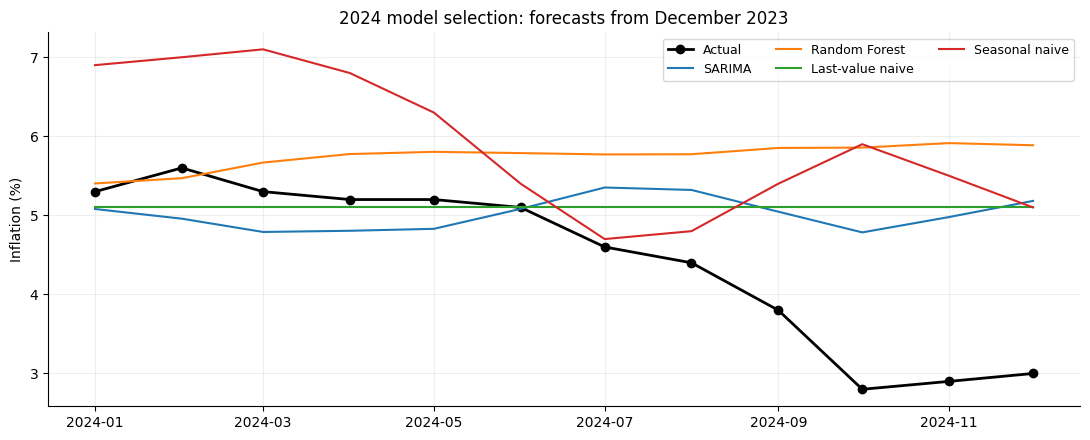

In [ ]:
MODEL_NAMES = ['SARIMA', 'Random Forest', 'Last-value naive', 'Seasonal naive']

def model_forecast(name, history, steps):
    dates = future_dates(history, steps)
    if name == 'SARIMA': return sarima_forecast(history, best_stat_params, steps)[0]
    if name == 'Random Forest': return rf_forecast(history, best_rf_params, steps)[0]
    if name == 'Last-value naive': return pd.Series(history.iloc[-1], index=dates)
    if name == 'Seasonal naive':
        return pd.Series(np.resize(history.iloc[-12:].to_numpy(), steps), index=dates)
    raise ValueError(name)

def backtest_origin(origin, names=MODEL_NAMES, steps=12):
    history = inflation.loc[:origin]
    records = []
    for name in names:
        predicted = model_forecast(name, history, steps)
        dates = future_dates(history, steps)
        assert predicted.index.equals(dates) and dates.min() > history.index.max()
        scale = np.mean(np.abs(np.diff(history.to_numpy())))
        for h, date in enumerate(dates, 1):
            records.append({'Model': name, 'Origin': origin, 'Month': date, 'Horizon': h,
                            'Actual': inflation.loc[date], 'Forecast': predicted.loc[date],
                            'MASE_scale': scale})
    return pd.DataFrame(records)

selection_predictions = backtest_origin(SELECTION_ORIGIN)
selection_comparison = pooled_metrics(selection_predictions)
winner = selection_comparison.iloc[0]['Model']
print('2024 selection: 12-step forecasts from December 2023')
display(selection_comparison)
print('Frozen winning model:', winner)
selection_predictions.to_csv(OUTPUT / 'selection_2024_predictions.csv', index=False)
selection_comparison.to_csv(OUTPUT / 'selection_2024_metrics.csv', index=False)

fig, ax = plt.subplots(figsize=(11, 4.5))
actual_selection = inflation.loc['2024-01-01':'2024-12-01']
ax.plot(actual_selection, color='black', linewidth=2, marker='o', label='Actual')
for name in MODEL_NAMES:
    group = selection_predictions.loc[selection_predictions.Model == name]
    ax.plot(group.Month, group.Forecast, label=name)
ax.set(title='2024 model selection: forecasts from December 2023', ylabel='Inflation (%)')
ax.legend(ncol=3, fontsize=9); ax.grid(alpha=0.2)
finish_figure('04_selection_2024.png')

## 7. Locked 2025 evaluation and supplementary monthly backtest
The 2025 year-ahead comparison uses the configurations and model choice already fixed. All models are refitted on January 2021–December 2024 and forecast January–December 2025 without seeing the actuals inside that path. We also show monthly one-step forecasts after earlier 2025 observations become available. The one-step results answer a different forecasting question and do not select the 2026 model.

2025 locked check: 12-step forecasts from December 2024


,Model,MAE_pp,RMSE_pp,sMAPE_pct,MASE,n_forecasts
0,Random Forest,0.2553,0.3209,8.0334,0.7498,12
1,Last-value naive,0.3333,0.3786,10.5316,0.9792,12
2,SARIMA,0.3223,0.4160,9.0819,0.9468,12
3,Seasonal naive,1.5500,1.7512,39.1320,4.5531,12


Winner remains: SARIMA
2025 supplementary monthly one-step check


,Model,MAE_pp,RMSE_pp,sMAPE_pct,MASE,n_forecasts
0,Last-value naive,0.1833,0.2415,5.7945,0.5643,12
1,SARIMA,0.1786,0.2526,5.6921,0.5438,12
2,Random Forest,0.1945,0.2554,6.1729,0.5966,12
3,Seasonal naive,1.5500,1.7512,39.1320,4.7101,12


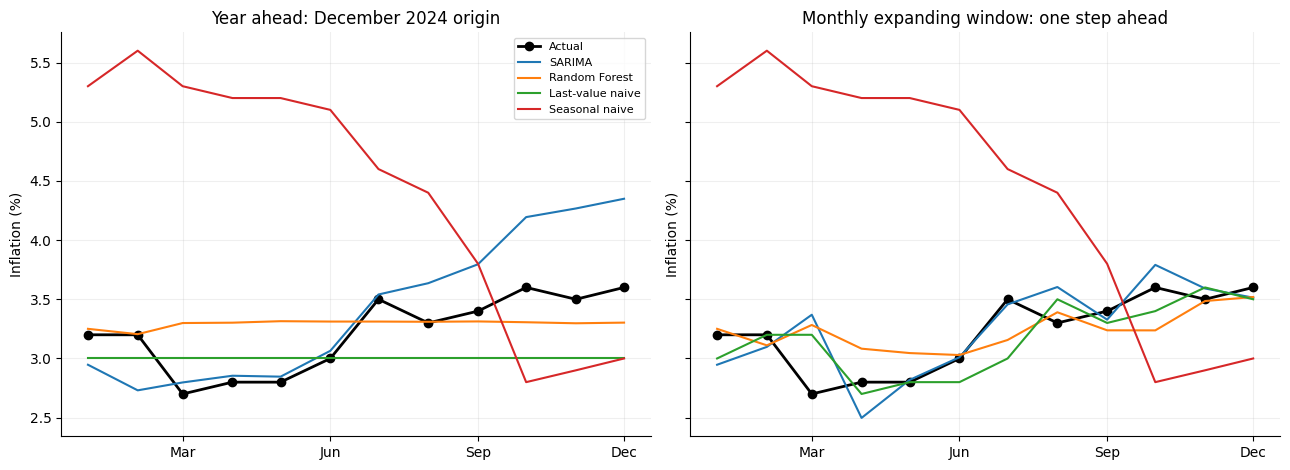

In [ ]:
locked_predictions = backtest_origin(CHECK_ORIGIN)
locked_comparison = pooled_metrics(locked_predictions)
print('2025 locked check: 12-step forecasts from December 2024')
display(locked_comparison)
print('Winner remains:', winner)

one_step_parts = []
for date in pd.date_range('2025-01-01', '2025-12-01', freq='MS'):
    one_step_parts.append(backtest_origin(date - pd.offsets.MonthBegin(1), steps=1))
one_step_predictions = pd.concat(one_step_parts, ignore_index=True)
one_step_comparison = pooled_metrics(one_step_predictions)
print('2025 supplementary monthly one-step check')
display(one_step_comparison)

for name, group in locked_predictions.groupby('Model'):
    assert group.Month.tolist() == list(pd.date_range('2025-01-01', '2025-12-01', freq='MS'))
    assert len(group) == 12
locked_predictions.to_csv(OUTPUT / 'locked_2025_predictions.csv', index=False)
locked_comparison.to_csv(OUTPUT / 'locked_2025_metrics.csv', index=False)
one_step_predictions.to_csv(OUTPUT / 'one_step_2025_predictions.csv', index=False)
one_step_comparison.to_csv(OUTPUT / 'one_step_2025_metrics.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, records, title in [(axes[0], locked_predictions, 'Year ahead: December 2024 origin'),
                           (axes[1], one_step_predictions, 'Monthly expanding window: one step ahead')]:
    ax.plot(inflation.loc['2025-01-01':], color='black', marker='o', linewidth=2, label='Actual')
    for name in MODEL_NAMES:
        group = records.loc[records.Model == name]
        ax.plot(group.Month, group.Forecast, label=name)
    ax.set_title(title); ax.set_ylabel('Inflation (%)'); ax.grid(alpha=0.2)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
axes[0].legend(fontsize=8)
finish_figure('05_locked_2025_backtests.png')

In [ ]:
selected_2024 = selection_comparison.set_index('Model').loc[winner]
selected_2025 = locked_comparison.set_index('Model').loc[winner]
rf_2025 = locked_comparison.set_index('Model').loc['Random Forest']
stat_2025 = locked_comparison.set_index('Model').loc['SARIMA']
display(Markdown(f"""### Interpretation of the comparison
The predeclared RMSE rule selected **{winner}** on 2024: RMSE **{selected_2024.RMSE_pp:.3f} percentage points** and MAE **{selected_2024.MAE_pp:.3f} percentage points**.

On the untouched 2025 year-ahead path, this frozen winner had RMSE **{selected_2025.RMSE_pp:.3f}** and MAE **{selected_2025.MAE_pp:.3f}**. The statistical model's RMSE was **{stat_2025.RMSE_pp:.3f}**, compared with **{rf_2025.RMSE_pp:.3f}** for Random Forest. Differences between the 2024 and 2025 rankings show that one validation year does not guarantee future superiority.

The 2025 year-ahead table contains only **one origin and 12 monthly errors**. These observations and the inflation rates themselves are serially dependent. We do not claim statistically significant superiority from this small comparison. The separately labelled one-step table must not be quoted as evidence of equivalent year-ahead accuracy.
"""))

<IPython.core.display.Markdown object>

## 8. Statistical-model residual diagnostics
Diagnostics use a refit through December 2024, before the locked check's targets. We remove the model's initial likelihood burn-in before residual analysis. The Ljung–Box lag-12 test is adjusted for fitted AR/MA parameters. Rejection indicates remaining serial dependence and weakens a white-noise interpretation; failure to reject does not establish correct specification. The Q–Q plot assesses the Gaussian approximation used for statistical prediction intervals.

Statistical model: {'order': (1, 1, 0), 'seasonal_order': (0, 0, 1, 12), 'trend': 'n'}
Fit converged: True | AIC: 44.302 | Residual count: 47


,lb_stat,lb_pvalue
12,19.9623,0.0296


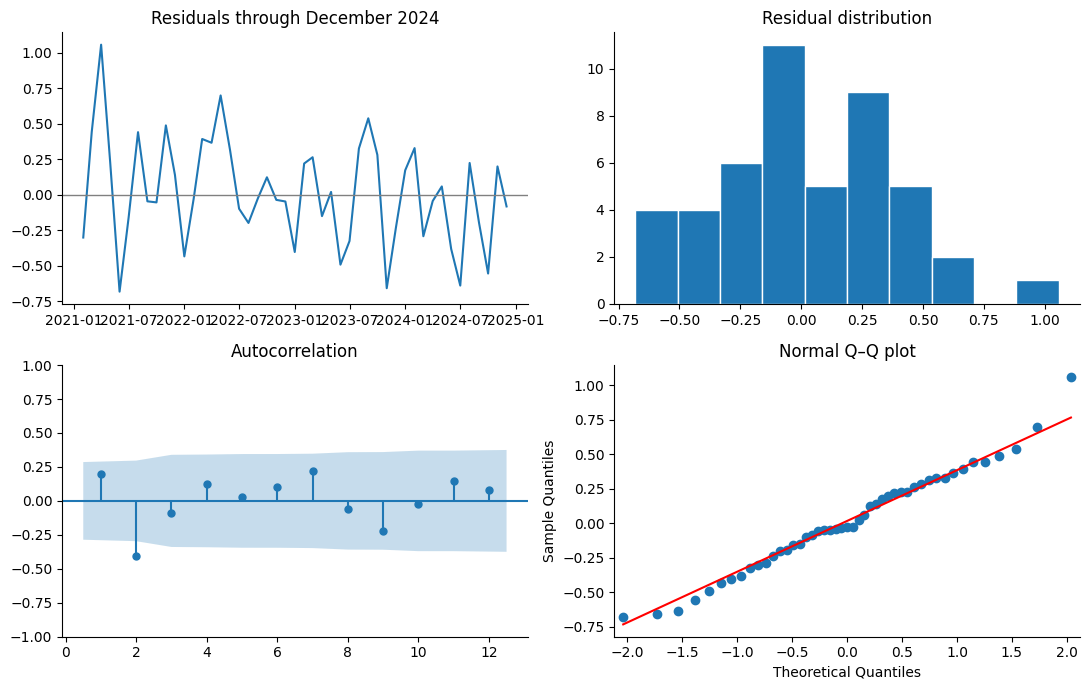

Ljung–Box adjusted p-value at lag 12: **0.0296**. Residual dependence remains at the 5% level.

In [ ]:
_, diagnostic_fit, _ = sarima_forecast(inflation.loc[:CHECK_ORIGIN], best_stat_params, 12)
burn = max(int(diagnostic_fit.loglikelihood_burn),
           sum(best_stat_params['order'][1:2]) + best_stat_params['seasonal_order'][1] * 12)
residuals = diagnostic_fit.resid.iloc[burn:]
residuals = residuals[np.isfinite(residuals)]
model_df = (best_stat_params['order'][0] + best_stat_params['order'][2]
             + best_stat_params['seasonal_order'][0] + best_stat_params['seasonal_order'][2])
ljung_box = acorr_ljungbox(residuals, lags=[12], model_df=model_df, return_df=True)
print('Statistical model:', best_stat_params)
print('Fit converged:', diagnostic_fit.mle_retvals.get('converged'),
      '| AIC:', round(diagnostic_fit.aic, 3), '| Residual count:', len(residuals))
display(ljung_box)
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0, 0].plot(residuals); axes[0, 0].axhline(0, color='grey', linewidth=1)
axes[0, 0].set_title('Residuals through December 2024')
axes[0, 1].hist(residuals, bins=10, edgecolor='white'); axes[0, 1].set_title('Residual distribution')
plot_acf(residuals, lags=12, ax=axes[1, 0], zero=False)
sm.qqplot(residuals, line='s', ax=axes[1, 1])
axes[1, 1].set_title('Normal Q–Q plot')
finish_figure('06_statistical_residuals.png')
lb_p = float(ljung_box.iloc[0]['lb_pvalue'])
display(Markdown(f"Ljung–Box adjusted p-value at lag 12: **{lb_p:.4f}**. " +
    ('Residual dependence remains at the 5% level.' if lb_p < 0.05 else
     'The test does not reject residual independence at 5%; its power is limited.')))

## 9. Full-sample refit and January–December 2026 forecast
The frozen winning configuration is refitted using all 2021–2025 target observations. For Random Forest, the full history creates 48 usable lag-feature rows. A statistical winner supplies conditional Gaussian 95% **pointwise prediction intervals**. RF and naive benchmarks do not supply calibrated intervals here; their bounds remain absent. The distribution of RF tree predictions is not a forecast prediction interval.

The selected statistical family is also refitted for transparency even if a benchmark or RF wins. Its intervals are labelled as belonging to that model only. Intervals do not include parameter-selection uncertainty, future policy or commodity shocks, source revisions, or uncertainty about the CPI basket. Negative lower bounds are possible for inflation and are not clipped.

,month,point_forecast,model,target,lower_95,upper_95
0,2026-01-01,3.4897,SARIMA,Headline year-on-year CPI inflation (%),2.8533,4.1261
1,2026-02-01,3.3651,SARIMA,Headline year-on-year CPI inflation (%),2.2545,4.4757
2,2026-03-01,3.7310,SARIMA,Headline year-on-year CPI inflation (%),2.2169,5.2450
3,2026-04-01,3.7048,SARIMA,Headline year-on-year CPI inflation (%),1.8448,5.5648
4,2026-05-01,3.6925,SARIMA,Headline year-on-year CPI inflation (%),1.5303,5.8548
5,2026-06-01,3.7187,SARIMA,Headline year-on-year CPI inflation (%),1.2872,6.1503
6,2026-07-01,3.7350,SARIMA,Headline year-on-year CPI inflation (%),1.0593,6.4106
7,2026-08-01,3.9262,SARIMA,Headline year-on-year CPI inflation (%),1.0263,6.8261
8,2026-09-01,3.9632,SARIMA,Headline year-on-year CPI inflation (%),0.8549,7.0715
9,2026-10-01,4.0992,SARIMA,Headline year-on-year CPI inflation (%),0.7956,7.4029


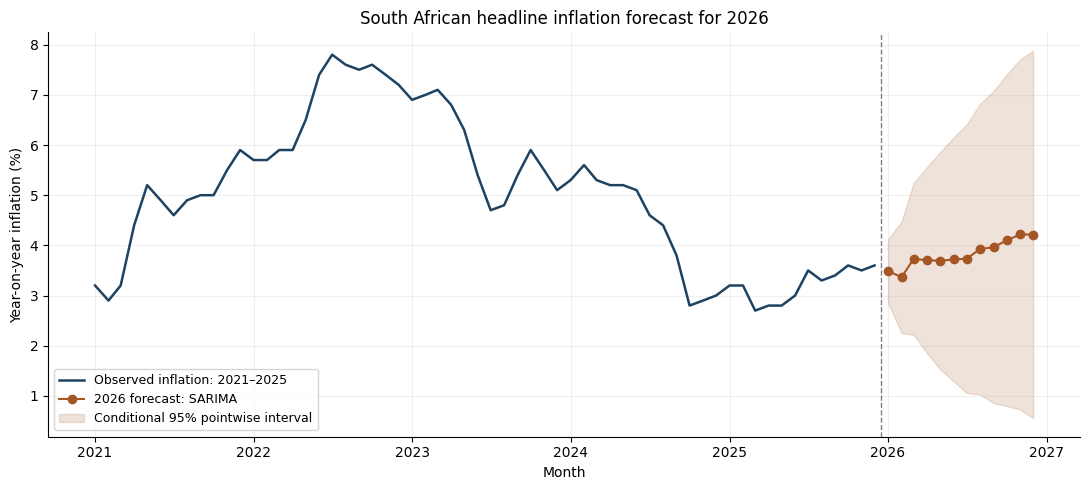

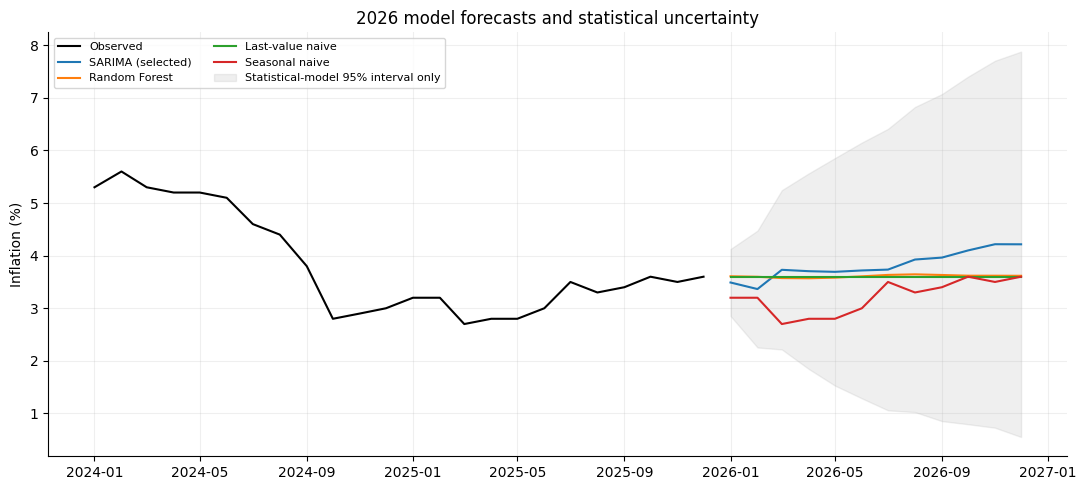

In [ ]:
stat_mean, final_stat_fit, stat_result = sarima_forecast(inflation, best_stat_params, 12)
stat_ci = stat_result.conf_int(alpha=0.05)
rf_mean, final_rf = rf_forecast(inflation, best_rf_params, 12)
dates_2026 = pd.date_range('2026-01-01', '2026-12-01', freq='MS')
forecast_paths = {'SARIMA': stat_mean, 'Random Forest': rf_mean,
                  'Last-value naive': model_forecast('Last-value naive', inflation, 12),
                  'Seasonal naive': model_forecast('Seasonal naive', inflation, 12)}
point_forecast = forecast_paths[winner]
assert point_forecast.index.equals(dates_2026)
forecast_2026 = pd.DataFrame({'month': dates_2026,
                             'point_forecast': point_forecast.to_numpy(),
                             'model': winner,
                             'target': 'Headline year-on-year CPI inflation (%)'})
if winner == 'SARIMA':
    forecast_2026['lower_95'] = stat_ci.iloc[:, 0].to_numpy()
    forecast_2026['upper_95'] = stat_ci.iloc[:, 1].to_numpy()
    assert (forecast_2026.lower_95 <= forecast_2026.point_forecast).all()
    assert (forecast_2026.upper_95 >= forecast_2026.point_forecast).all()
assert len(forecast_2026) == 12 and np.isfinite(forecast_2026.point_forecast).all()
display(forecast_2026)
forecast_2026.to_csv(OUTPUT / 'forecast_2026.csv', index=False)
alternative_forecasts = pd.DataFrame({'month': dates_2026,
                                      **{name: path.to_numpy() for name, path in forecast_paths.items()},
                                      'SARIMA_lower_95': stat_ci.iloc[:, 0].to_numpy(),
                                      'SARIMA_upper_95': stat_ci.iloc[:, 1].to_numpy()})
alternative_forecasts.to_csv(OUTPUT / 'alternative_forecasts_2026.csv', index=False)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(inflation, color='#1E4262', linewidth=1.8, label='Observed inflation: 2021–2025')
ax.plot(point_forecast, color='#A55625', marker='o', label=f'2026 forecast: {winner}')
if winner == 'SARIMA':
    ax.fill_between(dates_2026, forecast_2026.lower_95, forecast_2026.upper_95,
                     color='#A55625', alpha=0.17, label='Conditional 95% pointwise interval')
ax.axvline(pd.Timestamp('2025-12-15'), color='grey', linestyle='--', linewidth=1)
ax.set(title='South African headline inflation forecast for 2026',
       ylabel='Year-on-year inflation (%)', xlabel='Month')
ax.legend(fontsize=9); ax.grid(alpha=0.2)
finish_figure('07_selected_forecast_2026.png')

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(inflation.loc['2024-01-01':], color='black', label='Observed')
for name, path in forecast_paths.items():
    ax.plot(path, label=f'{name}' + (' (selected)' if name == winner else ''))
ax.fill_between(dates_2026, stat_ci.iloc[:, 0], stat_ci.iloc[:, 1], color='grey',
                 alpha=0.12, label='Statistical-model 95% interval only')
ax.set(title='2026 model forecasts and statistical uncertainty', ylabel='Inflation (%)')
ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.2)
finish_figure('08_forecast_model_comparison.png')

In [ ]:
annual_mean = float(forecast_2026.point_forecast.mean())
december_forecast = float(forecast_2026.point_forecast.iloc[-1])
display(Markdown(f"""### Forecast interpretation and limitations
The selected **{winner}** forecasts an average of the 12 monthly year-on-year inflation rates of **{annual_mean:.2f}%** in 2026, with **{december_forecast:.2f}%** in December. The monthly forecasts range from **{forecast_2026.point_forecast.min():.2f}%** to **{forecast_2026.point_forecast.max():.2f}%**. An average of monthly year-on-year rates is not the year-on-year change between annual-average CPI indices.

These forecasts extend patterns in the historical inflation series. They do not estimate causal effects of interest rates, exchange rates, food prices, fuel prices or electricity tariffs. Those shocks can change the realised path. A lower inflation rate means prices rise more slowly; only a negative rate implies prices below their level a year earlier.

Only 60 observations and five annual cycles are available. RF has just 48 supervised observations and can struggle with unfamiliar inflation regimes. The held-out year offers limited evidence, and year-on-year rates overlap and are serially dependent. The 2025 CPI basket/rebasing change and fixed publication vintage are further comparability limitations. The statistical residual Ljung–Box p-value is **{lb_p:.4f}**; remaining serial dependence weakens the model's white-noise error assumption. Statistical intervals are conditional approximations, and absent RF/benchmark intervals should not be interpreted as zero uncertainty. Updating the forecast after new releases would change the information set and requires a separately evaluated updating design.

No 2026 realised inflation, target-rate constraint, or desired 4% outcome enters tuning, selection or refitting.
"""))

results_summary = {'winner': winner, 'target': 'Official headline year-on-year CPI inflation (%)',
    'source_url': 'https://www.statssa.gov.za/publications/P0141/P0141December2025.pdf',
    'source_table': 'Table B2, printed page 4', 'source_release_date': '2026-01-21',
    'sample_start': '2021-01-01', 'sample_end': '2025-12-01', 'n_months': 60,
    'rf_supervised_rows': len(ml_data), 'stat_params': best_stat_params,
    'rf_params': best_rf_params, 'selection_origin': str(SELECTION_ORIGIN.date()),
    'locked_origin': str(CHECK_ORIGIN.date()), 'annual_mean_monthly_yoy_pct': annual_mean,
    'december_2026_yoy_pct': december_forecast, 'ljung_box_pvalue': lb_p,
    'interval_model': 'SARIMA' if winner == 'SARIMA' else None, 'versions': versions,
    'selection_metrics': selection_comparison.to_dict(orient='records'),
    'locked_metrics': locked_comparison.to_dict(orient='records'),
    'one_step_metrics': one_step_comparison.to_dict(orient='records'),
    'forecast': json.loads(forecast_2026.to_json(orient='records', date_format='iso')),
    'historical': json.loads(cpi_clean.reset_index().rename(columns={'date': 'month'}).to_json(
        orient='records', date_format='iso'))}
(OUTPUT / 'verified_results.json').write_text(json.dumps(results_summary, indent=2))
pd.DataFrame(stat_fit_log).to_csv(OUTPUT / 'statistical_fit_log.csv', index=False)
print('Saved forecast tables, metrics, source data, diagnostics and figures.')

### Forecast interpretation and limitations
The selected **SARIMA** forecasts an average of the 12 monthly year-on-year inflation rates of **3.82%** in 2026, with **4.22%** in December. The monthly forecasts range from **3.37%** to **4.22%**. An average of monthly year-on-year rates is not the year-on-year change between annual-average CPI indices.

These forecasts extend patterns in the historical inflation series. They do not estimate causal effects of interest rates, exchange rates, food prices, fuel prices or electricity tariffs. Those shocks can change the realised path. A lower inflation rate means prices rise more slowly; only a negative rate implies prices below their level a year earlier.

Only 60 observations and five annual cycles are available. RF has just 48 supervised observations and can struggle with unfamiliar inflation regimes. The held-out year offers limited evidence, and year-on-year rates overlap and are serially dependent. The 2025 CPI basket/rebasing change and fixed publication vintage are further comparability limitations. The statistical residual Ljung–Box p-value is **0.0296**; remaining serial dependence weakens the model's white-noise error assumption. Statistical intervals are conditional approximations, and absent RF/benchmark intervals should not be interpreted as zero uncertainty. Updating the forecast after new releases would change the information set and requires a separately evaluated updating design.

No 2026 realised inflation, target-rate constraint, or desired 4% outcome enters tuning, selection or refitting.


Saved forecast tables, metrics, source data, diagnostics and figures.


## 10. Required Excel forecast export
The deliverable must contain a month and point forecast for each of the 12 months in 2026. The following standard-library exporter writes a valid `.xlsx` without an additional Excel package. Dates are numeric Excel dates and forecasts are numeric values, with units labelled. Interval columns appear only when supported by the selected model. The accompanying formatted workbook provides the same verified forecast values.

In [ ]:
from zipfile import ZipFile, ZIP_DEFLATED
from xml.sax.saxutils import escape

def export_forecast_xlsx(frame, filename):
    columns = frame.columns.tolist()
    def excel_column(number):
        result = ''
        while number:
            number, rem = divmod(number - 1, 26)
            result = chr(65 + rem) + result
        return result
    rows = []
    for row_number, values in enumerate([columns] + frame.values.tolist(), 1):
        cells_xml = []
        for col_number, value in enumerate(values, 1):
            reference = f'{excel_column(col_number)}{row_number}'
            if row_number > 1 and col_number == 1:
                serial = (pd.Timestamp(value) - pd.Timestamp('1899-12-30')).days
                cell = f'<c r="{reference}" s="1"><v>{serial}</v></c>'
            elif isinstance(value, (int, float, np.number)):
                cell = f'<c r="{reference}" s="2"><v>{float(value):.15g}</v></c>'
            else:
                style = '3' if row_number == 1 else '0'
                cell = f'<c r="{reference}" s="{style}" t="inlineStr"><is><t>{escape(str(value))}</t></is></c>'
            cells_xml.append(cell)
        rows.append(f'<row r="{row_number}">' + ''.join(cells_xml) + '</row>')
    files_xml = {
      '[Content_Types].xml': '<Types xmlns="http://schemas.openxmlformats.org/package/2006/content-types"><Default Extension="rels" ContentType="application/vnd.openxmlformats-package.relationships+xml"/><Default Extension="xml" ContentType="application/xml"/><Override PartName="/xl/workbook.xml" ContentType="application/vnd.openxmlformats-officedocument.spreadsheetml.sheet.main+xml"/><Override PartName="/xl/worksheets/sheet1.xml" ContentType="application/vnd.openxmlformats-officedocument.spreadsheetml.worksheet+xml"/><Override PartName="/xl/styles.xml" ContentType="application/vnd.openxmlformats-officedocument.spreadsheetml.styles+xml"/></Types>',
      '_rels/.rels': '<Relationships xmlns="http://schemas.openxmlformats.org/package/2006/relationships"><Relationship Id="rId1" Type="http://schemas.openxmlformats.org/officeDocument/2006/relationships/officeDocument" Target="xl/workbook.xml"/></Relationships>',
      'xl/workbook.xml': '<workbook xmlns="http://schemas.openxmlformats.org/spreadsheetml/2006/main" xmlns:r="http://schemas.openxmlformats.org/officeDocument/2006/relationships"><sheets><sheet name="2026 Forecast" sheetId="1" r:id="rId1"/></sheets></workbook>',
      'xl/_rels/workbook.xml.rels': '<Relationships xmlns="http://schemas.openxmlformats.org/package/2006/relationships"><Relationship Id="rId1" Type="http://schemas.openxmlformats.org/officeDocument/2006/relationships/worksheet" Target="worksheets/sheet1.xml"/><Relationship Id="rId2" Type="http://schemas.openxmlformats.org/officeDocument/2006/relationships/styles" Target="styles.xml"/></Relationships>',
      'xl/styles.xml': '<styleSheet xmlns="http://schemas.openxmlformats.org/spreadsheetml/2006/main"><numFmts count="1"><numFmt numFmtId="164" formatCode="mmm yyyy"/></numFmts><fonts count="2"><font><sz val="11"/><name val="Arial"/></font><font><b/><sz val="11"/><name val="Arial"/></font></fonts><fills count="2"><fill><patternFill patternType="none"/></fill><fill><patternFill patternType="gray125"/></fill></fills><borders count="1"><border/></borders><cellStyleXfs count="1"><xf numFmtId="0" fontId="0" fillId="0" borderId="0"/></cellStyleXfs><cellXfs count="4"><xf numFmtId="0" fontId="0" fillId="0" borderId="0" xfId="0"/><xf numFmtId="164" fontId="0" fillId="0" borderId="0" xfId="0" applyNumberFormat="1"/><xf numFmtId="2" fontId="0" fillId="0" borderId="0" xfId="0" applyNumberFormat="1"/><xf numFmtId="0" fontId="1" fillId="0" borderId="0" xfId="0" applyFont="1"/></cellXfs><cellStyles count="1"><cellStyle name="Normal" xfId="0" builtinId="0"/></cellStyles></styleSheet>',
      'xl/worksheets/sheet1.xml': '<worksheet xmlns="http://schemas.openxmlformats.org/spreadsheetml/2006/main"><sheetViews><sheetView workbookViewId="0"/></sheetViews><cols><col min="1" max="1" width="16" customWidth="1"/><col min="2" max="2" width="20" customWidth="1"/><col min="3" max="3" width="22" customWidth="1"/><col min="4" max="4" width="52" customWidth="1"/><col min="5" max="6" width="18" customWidth="1"/></cols><sheetData>' + ''.join(rows) + '</sheetData></worksheet>'}
    with ZipFile(filename, 'w', ZIP_DEFLATED) as archive:
        for name, contents in files_xml.items(): archive.writestr(name, contents)

XLSX_PATH = OUTPUT / 'Buhle_Mbokodo_Reatile_Seekoei_2026_Inflation_Forecasts.xlsx'
export_forecast_xlsx(forecast_2026, XLSX_PATH)
with ZipFile(XLSX_PATH) as archive:
    assert 'xl/worksheets/sheet1.xml' in archive.namelist()
print('Excel forecast saved:', XLSX_PATH.name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Rubric coverage and conclusion
| Rubric component | Evidence in this notebook |
|---|---|
| Data collection and preparation (10) | Section 1: official source, 60 months, target justification, wide-to-monthly reshape, source checks and explanation of structural missingness |
| Backtesting (10) | Sections 3, 6–7: expanding origins, separate tuning/selection/check, common forecast dates, recursive multi-step ML, no future actuals within a path |
| Statistical model development (10) | Sections 2, 5 and 8: decomposition, ADF/KPSS/ACF/PACF, bounded ARIMA/SARIMA tuning, convergence logs and residual diagnostics |
| ML development (10) | Sections 4–7: explained causal predictors, RF tuning, recursive forecasts and comparison with statistical and naive forecasts |
| Evaluation (10) | Sections 6–10: MAE/RMSE/sMAPE/MASE, evidence-based frozen winner, locked historical check, 12 monthly 2026 forecasts, supported uncertainty and Excel export |

The final model is the one selected on historical validation, even if a later historical check favours another candidate. The evidence supports a conditional forecast, not a guaranteed inflation outcome. The notebook and Excel forecast are complete pipeline deliverables. The separate 8–10-page executive report should use the model-comparison tables, final forecast plot, limitations and references shown here.

## References
- Statistics South Africa (2026). *Consumer Price Index, December 2025*. P0141. Table B1 and B2, p. 4. Released 21 January 2026. https://www.statssa.gov.za/publications/P0141/P0141December2025.pdf
- Hyndman, R.J. and Athanasopoulos, G. (2021). *Forecasting: Principles and Practice*, 3rd ed. Section 5.10, time-series cross-validation. https://otexts.com/fpp3/tscv.html
- statsmodels developers. *SARIMAX API documentation*. https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html
- scikit-learn developers. *RandomForestRegressor API documentation*. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html
- University of the Free State (2026). *EDAB6808 Assignment 2: Anomaly Detection and Forecasting*. Question 2 and marking rubric.

The statistical and ML implementations adapt the group's supplied notebook using the cited library APIs. Source data are fixed to the documented release; dependency versions are printed in Section 1.